# Day 10/90 - How Do We Know a Model Is Actually Good?

In Day 9, we learned the main types of machine-learning problems.

Today is about a different question:

> **After we train a model, how do we know whether it actually works?**

A model can look excellent on the data it trained on and still fail when it sees new examples.

So Day 10 focuses on **evaluation**.

We will learn:

```text
1. train / validation / test splits
2. preprocessing and feature scaling
3. Pipelines
4. data leakage
5. overfitting
6. regression metrics
7. classification metrics
8. class imbalance
9. decision thresholds
10. ROC-AUC and PR-AUC
11. calibration
12. cross-validation
```

We will keep using a simple housing dataset.

For regression:

```text
house features
-> predict the sale price
```

For classification:

```text
house features
-> predict whether price is above $200,000
```

The goal is not to memorize formulas.

> **The goal is to understand what each evaluation tool tells us about the model and when we should use it.**

# 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    auc,
    ConfusionMatrixDisplay,
    roc_curve,
    precision_recall_curve,
    brier_score_loss
)
from sklearn.calibration import calibration_curve

# Load the Ames Housing dataset from OpenML.
# as_frame=True returns pandas DataFrames.
housing = fetch_openml(
    name="house_prices",
    as_frame=True,
    parser="auto"
)

raw = housing.frame.copy()

# Keep only beginner-friendly columns used in this lesson.
df = raw[
    [
        "GrLivArea",
        "BedroomAbvGr",
        "FullBath",
        "GarageCars",
        "YearBuilt",
        "SalePrice"
    ]
].copy()

# Rename the original dataset columns.
df = df.rename(columns={
    "GrLivArea": "living_area_sqft",
    "BedroomAbvGr": "bedrooms",
    "FullBath": "bathrooms",
    "GarageCars": "garage_spaces",
    "YearBuilt": "year_built",
    "SalePrice": "sale_price"
})

# Remove rows with missing values in the selected columns.
df = df.dropna().reset_index(drop=True)

df.head()

,living_area_sqft,bedrooms,bathrooms,garage_spaces,year_built,sale_price
0,1710,3,2,2,2003,208500
1,1262,3,2,2,1976,181500
2,1786,3,2,2,2001,223500
3,1717,3,1,3,1915,140000
4,2198,4,2,3,2000,250000


# 2. Train, Validation and Test Data

## The problem

Suppose we have data for 1,000 houses.

If we train the model on all 1,000 houses and then evaluate it on those **same houses**, a good score does not prove much.

The model has already seen them.

What we really want to know is:

> **Can the model make good predictions for houses it has never seen before?**

That ability is called **generalization**.

## Why split the data?

We divide the dataset into separate groups:

```text
TRAIN
-> the model learns from these examples

VALIDATION
-> we use these examples while deciding which model/settings are better

TEST
-> kept untouched until the very end for the final check
```

In this notebook we use roughly:

```text
70% train
15% validation
15% test
```

There is no universal perfect split. The exact percentages depend on how much data you have.

### Simple analogy

```text
TRAIN      = practice questions
VALIDATION = mock exam
TEST       = final exam
```

You can use the mock exam to figure out what you need to improve.

But if you repeatedly look at the final exam while studying, it is no longer a fair final exam.

That is why the **test set stays untouched until the end**.

In [2]:
# Features given to the model.
X = df[
    [
        "living_area_sqft",
        "bedrooms",
        "bathrooms",
        "garage_spaces",
        "year_built"
    ]
]

# Numerical target for regression.
y_price = df["sale_price"]

# First keep 70% for training and 30% for validation + test.
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y_price,
    test_size=0.30,
    random_state=42
)

# Split the remaining 30% equally:
# 15% validation and 15% final test.
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42
)

print("Train:", len(X_train))
print("Validation:", len(X_val))
print("Test:", len(X_test))

Train: 1022
Validation: 219
Test: 219


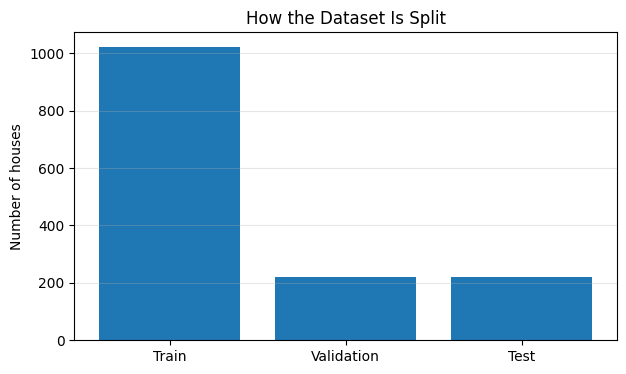

In [3]:
# Visualize how many examples are in each split.
split_names = ["Train", "Validation", "Test"]
split_sizes = [len(X_train), len(X_val), len(X_test)]

plt.figure(figsize=(7, 4))
plt.bar(split_names, split_sizes)
plt.ylabel("Number of houses")
plt.title("How the Dataset Is Split")
plt.grid(axis="y", alpha=0.3)
plt.show()

### What this graph shows

Each bar is a **different group of houses**.

```text
Train
-> largest group
-> model learns from these houses

Validation
-> smaller group
-> used while comparing choices

Test
-> smaller group
-> saved for the final check
```

The important idea is not the exact bar height. It is that the three groups are **separate**.

A house in the test set should not help the model learn before the final evaluation.

# 3. Preprocessing

## What is preprocessing?

**Data preprocessing means cleaning, organizing, or transforming raw data into a form that a machine-learning model can use correctly.**

Real-world data is often messy.

For example:

```text
missing values
duplicate rows
text categories
wrong data types
irrelevant columns
numerical features measured on very different scales
```

So the general flow is:

```text
raw data
-> preprocessing
-> model-ready data
-> model
```

Preprocessing can include:

```text
fill or remove missing values
remove duplicates
convert categories into numbers
fix data types
select useful features
scale numerical features
```

Our housing data is already fairly clean, so here we focus on **feature scaling**.

---

## What is feature scaling?

Feature scaling changes the **numerical representation** of a feature so that features measured in very different units can be put on a more comparable numerical scale.

Suppose a house has:

```text
living area = 1800 sq ft
bedrooms    = 3
bathrooms   = 2
```

The model receives numbers like:

```text
1800, 3, 2
```

`1800` is numerically much larger than `3` or `2`.

For some algorithms, that difference in scale can affect calculations such as distances, optimization, or regularization.

Scaling changes the numbers the model works with, but it does **not** change the underlying house.

```text
1800 sq ft is still 1800 sq ft
3 bedrooms is still 3 bedrooms
```

We are only giving the model a different numerical representation.

> **Scaling does not make every feature equally important. The model can still learn that some features matter more than others.**

---

## Min-max scaling

Min-max scaling often converts a feature into a range such as:

```text
0 to 1
```

Example:

```text
original:
1000, 1500, 2000

scaled:
0.0, 0.5, 1.0
```

The ordering is still the same:

```text
1000 < 1500 < 2000
```

---

## Standardization

**Standardization describes each value by how far it is from that feature's average, measured using the feature's standard deviation.**

Suppose living area has:

```text
mean = 1500 sq ft
standard deviation = 500 sq ft
```

Now consider three houses:

```text
1000 sq ft -> about -1
1500 sq ft -> about  0
2000 sq ft -> about +1
```

What do those new numbers mean?

```text
-1 -> about one standard deviation below average
 0 -> around average
+1 -> about one standard deviation above average
```

So instead of the model only seeing:

```text
2000
```

it can work with the idea:

```text
"this value is about one standard deviation above the typical value"
```

`StandardScaler` learns the **mean and standard deviation from the training data**, then uses those same values to transform validation, test, and future data.

> **Important:** plain `LinearRegression` does not require standardization to produce valid predictions. We use scaling here to learn the preprocessing workflow because many other ML algorithms are sensitive to feature scale.

## Code example: preprocessing messy data

Before using a real ML dataset, here is a tiny example so you can **see what preprocessing actually does**.

Imagine we receive this raw data:

```text
missing living area
duplicate row
text category ("urban", "suburban")
```

We will:

```text
1. fill the missing numerical value
2. remove the duplicate row
3. convert the text category into numerical columns
```

This is preprocessing because we are turning messy/raw data into data a model can work with.

In [4]:
# --- PREPROCESSING DEMO ---

# Create a tiny intentionally messy dataset.
messy_data = pd.DataFrame({
    "living_area_sqft": [1200, 1800, np.nan, 1800],
    "bedrooms": [2, 3, 4, 3],
    "location": ["suburban", "urban", "urban", "urban"]
})

print("RAW DATA:")
display(messy_data)

# Make a copy so we do not change the original example.
clean_data = messy_data.copy()

# 1. Fill the missing living-area value with the median.
median_area = clean_data["living_area_sqft"].median()

clean_data["living_area_sqft"] = (
    clean_data["living_area_sqft"]
    .fillna(median_area)
)

# 2. Remove duplicate rows.
clean_data = clean_data.drop_duplicates()

# 3. Convert the text category into numerical 0/1 columns.
# Example:
# location_suburban = 1 means the row is suburban.
# location_urban = 1 means the row is urban.
clean_data = pd.get_dummies(
    clean_data,
    columns=["location"],
    dtype=int
)

print("\nAFTER PREPROCESSING:")
display(clean_data)

RAW DATA:


,living_area_sqft,bedrooms,location
0,1200.0,2,suburban
1,1800.0,3,urban
2,NaN,4,urban
3,1800.0,3,urban



AFTER PREPROCESSING:


,living_area_sqft,bedrooms,location_suburban,location_urban
0,1200.0,2,1,0
1,1800.0,3,0,1
2,1800.0,4,0,1


### What changed?

The first table is the **raw data**.

The second table is more model-ready:

```text
missing value
-> filled with the median

duplicate row
-> removed

text such as "urban"
-> converted into numerical columns
```

Notice that preprocessing did **not** mean one specific operation.

It was a collection of steps needed to prepare the data.

Different datasets need different preprocessing.

## Code example: feature scaling

Now let us isolate **feature scaling** so you can see exactly what changes.

We will use three simple houses:

```text
living area: 1000, 1500, 2000
bedrooms:       2,    3,    4
```

`StandardScaler` will replace each raw value with a number that describes where it sits relative to that feature's mean and standard deviation.

In [5]:
# --- FEATURE SCALING DEMO ---

scale_example = pd.DataFrame({
    "living_area_sqft": [1000, 1500, 2000],
    "bedrooms": [2, 3, 4]
})

print("ORIGINAL VALUES:")
display(scale_example)

# Create the scaler.
demo_scaler = StandardScaler()

# Learn the mean/std of each column,
# then transform the values.
scaled_values = demo_scaler.fit_transform(
    scale_example
)

# Convert the NumPy result back to a DataFrame
# so it is easier to read.
scaled_example = pd.DataFrame(
    scaled_values,
    columns=[
        "living_area_scaled",
        "bedrooms_scaled"
    ]
)

comparison = pd.concat(
    [
        scale_example.reset_index(drop=True),
        scaled_example
    ],
    axis=1
)

print("\nORIGINAL AND SCALED VALUES SIDE BY SIDE:")
display(comparison.round(2))

print("\nMeans learned by StandardScaler:")
print(
    dict(
        zip(
            scale_example.columns,
            np.round(demo_scaler.mean_, 2)
        )
    )
)

ORIGINAL VALUES:


,living_area_sqft,bedrooms
0,1000,2
1,1500,3
2,2000,4



ORIGINAL AND SCALED VALUES SIDE BY SIDE:


,living_area_sqft,bedrooms,living_area_scaled,bedrooms_scaled
0,1000,2,-1.22,-1.22
1,1500,3,0.00,0.00
2,2000,4,1.22,1.22



Means learned by StandardScaler:
{'living_area_sqft': np.float64(1500.0), 'bedrooms': np.float64(3.0)}


### How to read the scaled values

For this tiny example:

```text
1500 sq ft
-> scaled value 0
```

because `1500` is the average living area.

```text
1000 sq ft
-> negative scaled value
```

because it is below the average.

```text
2000 sq ft
-> positive scaled value
```

because it is above the average.

The same idea happens independently for the `bedrooms` column.

So the transformation is:

```text
original real-world value
-> position relative to that feature's typical values
```

The original information has not disappeared. We have changed the **numerical representation used by the model**.

After this simple demo, the next code cell applies `StandardScaler` to our actual housing training data.

In [6]:
# Now apply the same idea to the REAL housing training data.

# Create StandardScaler.
scaler = StandardScaler()

# fit_transform(X_train) does TWO things:
#
# 1. FIT:
#    learn the mean and standard deviation of EACH feature
#    using training data only.
#
# 2. TRANSFORM:
#    convert each training value into its standardized value.
scaled_train = scaler.fit_transform(
    X_train
)

# IMPORTANT:
# Validation data must NOT teach the scaler new mean/std values.
#
# transform() reuses what was learned from X_train.
scaled_val = scaler.transform(
    X_val
)

print("Original training data:")
display(X_train.head())

scaled_train_df = pd.DataFrame(
    scaled_train,
    columns=X_train.columns,
    index=X_train.index
)

print("\nStandardized training data:")
display(
    scaled_train_df.head().round(2)
)

Original training data:


,living_area_sqft,bedrooms,bathrooms,garage_spaces,year_built
135,1682,3,2,2,1970
1452,1072,2,1,2,2005
762,1547,3,2,2,2009
932,1905,3,2,3,2006
435,1661,3,2,2,1996



Standardized training data:


,living_area_sqft,bedrooms,bathrooms,garage_spaces,year_built
135,0.29,0.14,0.77,0.30,-0.03
1452,-0.86,-1.10,-1.07,0.30,1.11
762,0.03,0.14,0.77,0.30,1.24
932,0.71,0.14,0.77,1.67,1.14
435,0.25,0.14,0.77,0.30,0.81


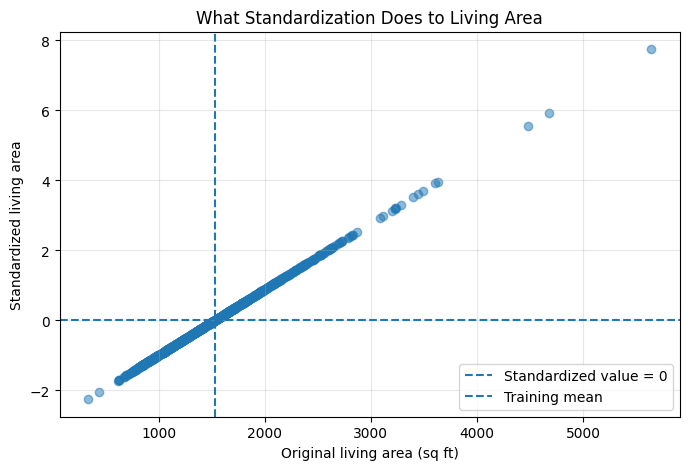

In [7]:
# Visualize what standardization does to ONE feature: living area.
#
# x-axis = original living area in square feet
# y-axis = standardized value used by the model
living_area_index = X_train.columns.get_loc("living_area_sqft")
original_living_area = X_train["living_area_sqft"].to_numpy()
standardized_living_area = scaled_train[:, living_area_index]

plt.figure(figsize=(8, 5))
plt.scatter(original_living_area, standardized_living_area, alpha=0.5)

# The training mean becomes approximately 0 after standardization.
plt.axhline(0, linestyle="--", label="Standardized value = 0")
plt.axvline(
    X_train["living_area_sqft"].mean(),
    linestyle="--",
    label="Training mean"
)

plt.xlabel("Original living area (sq ft)")
plt.ylabel("Standardized living area")
plt.title("What Standardization Does to Living Area")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### How to read this graph

Each dot is one house.

The **x-axis** shows the real living area:

```text
1000 sq ft
1500 sq ft
2000 sq ft
...
```

The **y-axis** shows the number the model receives after standardization.

The dashed vertical line is the average living area in the training data. Where that line meets the data, the standardized value is around:

```text
0
```

So:

```text
house near the average
-> standardized value near 0

house larger than average
-> positive standardized value

house smaller than average
-> negative standardized value
```

If a house is about one standard deviation above the average, its standardized value is about `+1`.

**Nothing about the house changed.** We only changed how its living-area number is represented for the model.

# 4. Data Leakage

**Data leakage happens when information that should not be available to the model accidentally influences training or model selection.**

The dangerous part is that leakage often makes the model look **better than it really is**.

There are two useful ways to think about leakage.

## 1. The model gets part of the answer

Suppose we want to predict:

```text
Will this customer cancel?
```

and we give the model:

```text
account_closed_date
```

That information may only exist **after** the customer has already cancelled.

The model is being given a clue from the future.

Its evaluation score may look great, but that feature would not exist when we need to make the real prediction.

## 2. Evaluation data leaks into training

Suppose we calculate scaling statistics using the entire dataset:

```text
train + validation + test
```

and only split the data afterward.

Now the mean and standard deviation used during training contain information from the validation/test examples.

The model has indirectly learned something about the data that was supposed to judge it.

Correct workflow:

```text
split data first
-> learn preprocessing from TRAIN only
-> apply that learned preprocessing to validation/test
```

> **Simple rule: data used to judge the model should not help the model learn.**

## What is a Pipeline?

A **scikit-learn Pipeline** connects preprocessing and the model into one ordered workflow.

In this notebook:

```text
raw house features
-> StandardScaler
-> LinearRegression
-> predicted price
```

### Why is this useful?

Without a Pipeline, we would have to remember to do this manually:

```text
1. learn scaling values from X_train
2. scale X_train
3. train the model
4. scale X_val using the SAME training values
5. make predictions
```

If we accidentally fit a new scaler on validation or test data, our evaluation becomes incorrect.

A Pipeline keeps these steps together.

### What happens during `fit()`?

```python
reg_pipeline.fit(X_train, y_train)
```

means:

```text
X_train
-> StandardScaler learns mean/std from X_train
-> X_train is standardized
-> LinearRegression learns from the standardized X_train
```

### What happens during `predict()`?

```python
reg_pipeline.predict(X_val)
```

means:

```text
X_val
-> use the SAME mean/std learned from X_train
-> standardize X_val
-> send it to the trained model
-> return predictions
```

So the simplest mental model is:

> **Pipeline = keep the preprocessing steps and model together so they are applied consistently every time.**

In [8]:
# A Pipeline keeps preprocessing and the model together.
# raw features -> StandardScaler -> LinearRegression
reg_pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("model", LinearRegression())
])

# fit() learns the scaler values and the model parameters
# from the training data only.
reg_pipeline.fit(X_train, y_train)

# Predict prices for validation rows the model did not train on.
val_predictions = reg_pipeline.predict(X_val)

# MAE = average absolute difference between predicted and real prices.
val_mae = mean_absolute_error(
    y_val,
    val_predictions
)

print("Validation MAE: $", round(val_mae, 2))

Validation MAE: $ 30045.25


# 5. Overfitting

**Overfitting happens when a model matches the training data so closely that it learns details that do not help on new data.**

Those details can include:

```text
noise
outliers
accidental patterns
very specific combinations that only occurred in training
```

### Example

Imagine a decision tree predicting house prices.

A small tree might learn broad patterns such as:

```text
larger house -> usually more expensive
newer house  -> often more expensive
more garage spaces -> often more expensive
```

A very deep tree can keep creating more and more branches until it starts learning extremely specific training examples.

It may effectively learn:

```text
"If a house looks almost exactly like this training house,
predict almost exactly its training price."
```

That can make training error extremely low.

But when a different house appears, those memorized details may not help.

### Typical pattern

```text
training error   -> keeps getting lower
validation error -> improves at first, then stops improving or gets worse
```

That growing gap is a common sign of overfitting.

Compare:

```text
UNDERFITTING
-> model is too simple
-> performs poorly even on training data

GOOD FIT
-> learns useful patterns
-> performs well on unseen data

OVERFITTING
-> performs extremely well on training data
-> performs noticeably worse on unseen data
```

The goal is **not** the lowest possible training error.

> **The goal is to learn patterns that generalize to new data.**

In [9]:
# Try trees with different maximum depths.
# Larger depth -> more flexible / complex model.
depths = [2, 4, 8, 16, None]

# Store training and validation errors for each tree.
train_mae = []
val_mae_tree = []

for depth in depths:
    # Create one decision tree.
    tree = DecisionTreeRegressor(
        max_depth=depth,
        random_state=42
    )

    # Learn from training data.
    tree.fit(X_train, y_train)

    # Error on data the tree already saw.
    train_mae.append(
        mean_absolute_error(
            y_train,
            tree.predict(X_train)
        )
    )

    # Error on validation data the tree did not train on.
    val_mae_tree.append(
        mean_absolute_error(
            y_val,
            tree.predict(X_val)
        )
    )

# Put the comparison into a table.
pd.DataFrame({
    "max_depth": [2, 4, 8, 16, "None"],
    "train_MAE": np.round(train_mae, 0),
    "validation_MAE": np.round(val_mae_tree, 0)
})

,max_depth,train_MAE,validation_MAE
0,2,37626.0,37801.0
1,4,28156.0,29628.0
2,8,16059.0,30338.0
3,16,1273.0,34260.0
4,None,318.0,34736.0


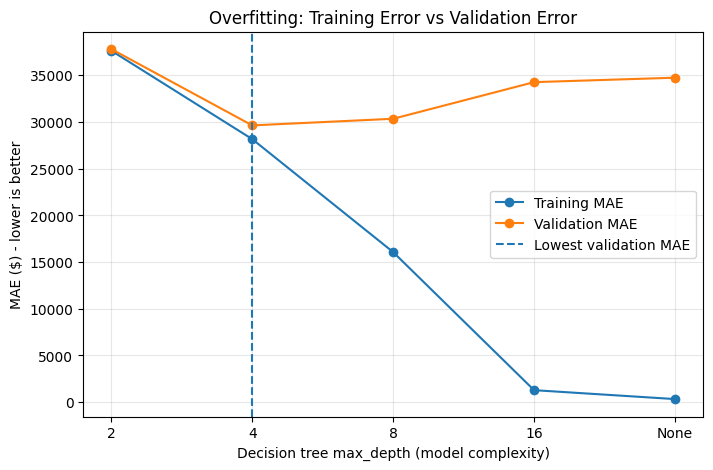

In [10]:
# Draw training and validation error as tree complexity increases.
plt.figure(figsize=(8, 5))

positions = range(len(depths))
depth_labels = [2, 4, 8, 16, "None"]

plt.plot(positions, train_mae, marker="o", label="Training MAE")
plt.plot(positions, val_mae_tree, marker="o", label="Validation MAE")

# Find the tree depth with the lowest validation error.
best_index = int(np.argmin(val_mae_tree))
plt.axvline(
    best_index,
    linestyle="--",
    label="Lowest validation MAE"
)

plt.xticks(positions, depth_labels)
plt.xlabel("Decision tree max_depth (model complexity)")
plt.ylabel("MAE ($) - lower is better")
plt.title("Overfitting: Training Error vs Validation Error")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### How this graph explains overfitting

The x-axis moves from **simpler trees to more complex trees**.

The y-axis is MAE:

```text
lower MAE = smaller prediction error
```

There are two lines:

```text
Training MAE
-> error on houses the tree learned from

Validation MAE
-> error on new houses the tree did not train on
```

Now watch what happens as the tree becomes more complex:

```text
training error
-> usually keeps falling

validation error
-> may fall at first
-> then stop improving or rise
```

Why?

A more complex tree can keep fitting tiny details of the training set. Those details help it on the training houses but may not help on new houses.

The dashed vertical line marks the depth with the **lowest validation MAE** among the depths we tried.

That is the core visual sign of overfitting:

> **Training keeps improving while unseen-data performance stops improving or becomes worse.**

# 6. Regression Metrics

Regression predicts a **number**.

For our housing example:

```text
actual price    = $250,000
predicted price = $230,000
```

The model missed by:

```text
$20,000
```

A regression metric converts many prediction mistakes into a number that tells us how well the model is doing.

We will use:

```text
MAE
MSE
```

## A. MAE - Mean Absolute Error

**MAE tells us the average size of the model's prediction mistakes.**

For each house:

```text
error size = |actual price - predicted price|
```

We use the absolute value because we care about **how large the mistake was**, not whether the model predicted too high or too low.

Example:

```text
House 1 error = $10,000
House 2 error = $20,000
House 3 error = $30,000
```

Average:

```text
MAE = $20,000
```

So if our model reports:

```text
MAE = $25,000
```

a useful interpretation is:

> **The model's predicted house prices are off by about $25,000 on average.**

Why MAE is useful:

```text
target is dollars
MAE is also dollars
```

So it is easy to explain and interpret.

In [11]:
# Train using the training split.
reg_pipeline.fit(X_train, y_train)

# During development, evaluate on VALIDATION data.
# The final test set stays untouched until the end.
val_price_predictions = reg_pipeline.predict(X_val)

val_mae = mean_absolute_error(
    y_val,
    val_price_predictions
)

print("Validation MAE: $", round(val_mae, 2))

Validation MAE: $ 30045.25


## B. MSE - Mean Squared Error

**MSE measures prediction error too, but it makes large mistakes matter much more than small mistakes.**

It does this by **squaring each error before averaging**.

Example:

```text
error = 10
10² = 100

error = 100
100² = 10,000
```

The second error is 10 times larger, but after squaring it contributes 100 times as much.

That means a few very large mistakes can increase MSE strongly.

### MAE vs MSE

```text
MAE
-> treats errors more evenly
-> easy to interpret in the original unit

MSE
-> heavily penalizes large errors
-> useful when large mistakes are especially undesirable
-> result is in squared units, so it is less intuitive to read directly
```

For house prices:

```text
MAE -> directly interpretable in dollars
MSE -> mainly useful for comparing/optimizing error, not as a dollar amount
```

In [12]:
# MSE squares each prediction error before averaging,
# so large mistakes contribute much more strongly.
val_mse = mean_squared_error(
    y_val,
    val_price_predictions
)

print("Validation MSE:", round(val_mse, 2))

Validation MSE: 1597323072.25


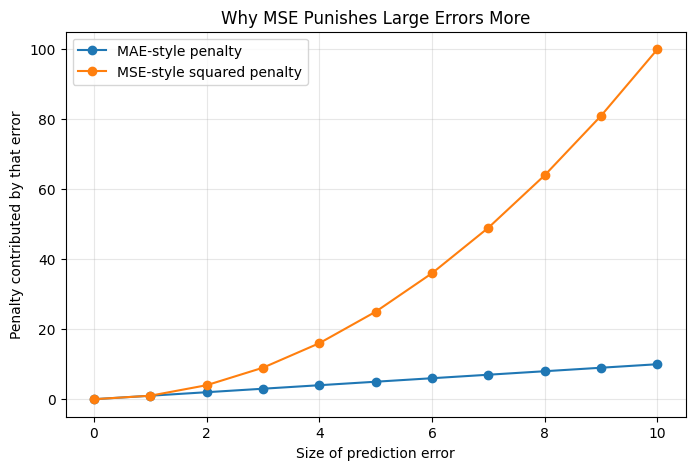

In [13]:
# Illustrative graph: how MAE and MSE treat increasingly large errors.
# These are simple example error sizes, not predictions from the housing model.
error_sizes = np.arange(0, 11)
mae_penalty = error_sizes
mse_penalty = error_sizes ** 2

plt.figure(figsize=(8, 5))
plt.plot(error_sizes, mae_penalty, marker="o", label="MAE-style penalty")
plt.plot(error_sizes, mse_penalty, marker="o", label="MSE-style squared penalty")
plt.xlabel("Size of prediction error")
plt.ylabel("Penalty contributed by that error")
plt.title("Why MSE Punishes Large Errors More")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### What this graph shows

For MAE, the penalty grows in a straight line:

```text
error 2  -> penalty 2
error 5  -> penalty 5
error 10 -> penalty 10
```

For MSE, the error is squared:

```text
error 2  -> penalty 4
error 5  -> penalty 25
error 10 -> penalty 100
```

That is why the MSE line bends upward quickly.

So if your application considers a few **very large mistakes especially bad**, MSE reacts to them much more strongly than MAE.

# 7. Classification Metrics

Classification predicts a **category**.

For our housing example:

```text
0 -> house price is $200,000 or below
1 -> house price is above $200,000
```

The classifier first produces a probability for class `1`.

Example:

```text
P(above $200k) = 0.82
```

Using a threshold of `0.5`, that becomes:

```text
0.82 >= 0.5
-> predict class 1
```

Now we need metrics that tell us **what kinds of classification decisions the model is getting right or wrong**.

We use validation data for these comparisons so the final test set remains untouched.

In [14]:
# Binary target:
# 0 = $200,000 or below
# 1 = above $200,000
y_class = (
    df["sale_price"] > 200_000
).astype(int)

# 70% training, 30% validation + test.
X_train_c, X_temp_c, y_train_c, y_temp_c = train_test_split(
    X,
    y_class,
    test_size=0.30,
    random_state=42,
    stratify=y_class
)

# Split the remaining 30% into 15% validation and 15% final test.
X_val_c, X_test_c, y_val_c, y_test_c = train_test_split(
    X_temp_c,
    y_temp_c,
    test_size=0.50,
    random_state=42,
    stratify=y_temp_c
)

class_pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
])

class_pipeline.fit(
    X_train_c,
    y_train_c
)

# Probability of class 1 on VALIDATION data.
class_probabilities = class_pipeline.predict_proba(
    X_val_c
)[:, 1]

# Default decision threshold = 0.5.
class_predictions = (
    class_probabilities >= 0.5
).astype(int)

print("Probabilities:", np.round(class_probabilities[:8], 3))
print("Predictions :", class_predictions[:8])
print("Actual      :", y_val_c.to_numpy()[:8])

Probabilities: [0.014 0.081 0.005 0.002 0.006 0.004 0.811 0.146]
Predictions : [0 0 0 0 0 0 1 0]
Actual      : [0 1 0 0 0 0 1 0]


## A. Confusion Matrix

A confusion matrix is a table showing the four possible outcomes of a binary classification prediction.

For our example:

```text
POSITIVE = house is above $200k
NEGATIVE = house is $200k or below
```

| | Actually positive | Actually negative |
|---|---|---|
| **Predicted positive** | True Positive (TP) | False Positive (FP) |
| **Predicted negative** | False Negative (FN) | True Negative (TN) |

What each one means:

```text
TRUE POSITIVE
predicted above $200k
actually above $200k
-> correct

FALSE POSITIVE
predicted above $200k
actually $200k or below
-> false alarm

TRUE NEGATIVE
predicted $200k or below
actually $200k or below
-> correct

FALSE NEGATIVE
predicted $200k or below
actually above $200k
-> missed positive
```

Why do we need this?

Because saying:

```text
"the model made 20 mistakes"
```

does not tell us **which mistakes** it made.

A confusion matrix separates false alarms from missed positives.

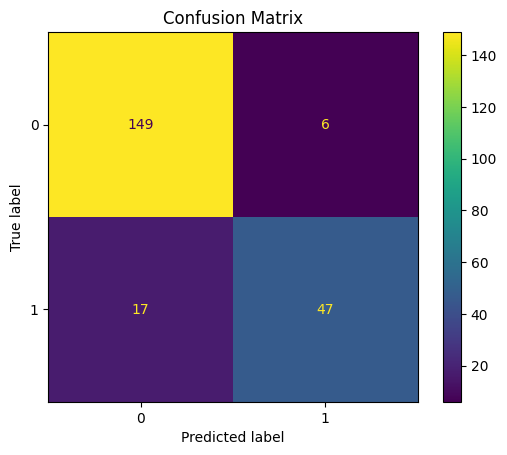

In [15]:
# Compare the real labels with model predictions
# and display TP, FP, TN, and FN counts.
ConfusionMatrixDisplay.from_predictions(
    y_val_c,
    class_predictions
)

plt.title("Confusion Matrix")
plt.show()

### How to read the confusion matrix

Look at the **off-diagonal cells** to find mistakes:

```text
False Positive
-> model predicted positive but reality was negative

False Negative
-> model predicted negative but reality was positive
```

Which one matters more depends on the application.

A fraud system may care strongly about false negatives because they represent fraud that was missed.

A system that automatically blocks users may care strongly about false positives because they represent innocent users who were blocked.

## B. Accuracy

**Accuracy answers: "Out of every prediction the model made, what percentage were correct?"**

Example:

```text
100 total predictions
90 correct
10 wrong
```

Then:

```text
accuracy = 90 / 100 = 90%
```

Accuracy is useful when the classes are reasonably balanced and different mistakes have similar importance.

But accuracy can hide serious problems when one class is rare.

We will see that in the class-imbalance section.

In [16]:
# Accuracy = correct predictions / all predictions.
accuracy = accuracy_score(
    y_val_c,
    class_predictions
)

print("Accuracy:", round(accuracy, 3))

Accuracy: 0.895


## C. Precision

**Precision looks only at the examples the model predicted as positive.**

It asks:

> **When the model says "positive", how often is it actually correct?**

Fraud example:

```text
model flags 10 transactions as fraud
8 really are fraud
2 are actually normal
```

So:

```text
precision = 8 / 10 = 80%
```

The denominator is:

```text
everything the MODEL predicted as positive
```

High precision means the model produces **fewer false alarms**.

Use precision when false positives are expensive.

Examples:

```text
spam filter deleting an important email
fraud system blocking a legitimate payment
content moderation incorrectly removing safe content
```

In [17]:
# Precision asks:
# "When the model predicts positive, how often is it correct?"
precision = precision_score(
    y_val_c,
    class_predictions
)

print("Precision:", round(precision, 3))

Precision: 0.887


## D. Recall

**Recall starts from the examples that really are positive.**

It asks:

> **Of all the real positive cases, how many did the model successfully find?**

Fraud example:

```text
10 transactions are actually fraud
model catches 9
model misses 1
```

So:

```text
recall = 9 / 10 = 90%
```

The denominator is:

```text
everything that is ACTUALLY positive
```

High recall means the model misses fewer real positives.

Use recall when false negatives are expensive.

Examples:

```text
missing a fraudulent payment
missing a dangerous defect
missing a relevant document that must be retrieved
```

### Precision vs Recall

A useful way to remember:

```text
PRECISION
start from what the MODEL called positive

RECALL
start from what is ACTUALLY positive
```

In [18]:
# Recall asks:
# "Of all the real positive examples, how many did the model catch?"
recall = recall_score(
    y_val_c,
    class_predictions
)

print("Recall:", round(recall, 3))

Recall: 0.734


## E. F1 Score

Precision and recall can move in opposite directions.

Example:

A very cautious fraud model might only flag the most obvious cases:

```text
precision = 95%
recall    = 30%
```

That means:

```text
when it flags fraud -> usually correct
but
it misses many real fraud cases
```

Another model might flag almost everything:

```text
recall    = very high
precision = low
```

It catches most fraud, but creates many false alarms.

**F1 combines precision and recall into one score and becomes high only when both are reasonably strong.**

So F1 is useful when:

```text
false positives matter
AND
false negatives matter
```

For Day 10, you do not need to memorize the F1 formula.

You need to understand what problem it solves:

> **It prevents us from looking at only precision or only recall and ignoring the other one.**

In [19]:
# F1 combines precision and recall into one score.
f1 = f1_score(
    y_val_c,
    class_predictions
)

print("F1:", round(f1, 3))

F1: 0.803


# 8. Class Imbalance

**Class imbalance means one class appears much more often than another.**

Example:

```text
95 normal transactions
5 fraud transactions
```

Now imagine a completely useless model:

```text
predict "normal" for every transaction
```

It gets:

```text
95 correct
5 wrong

accuracy = 95%
```

That sounds impressive.

But ask the question we actually care about:

```text
How many fraud cases did it catch?
```

Answer:

```text
0 out of 5
```

So the model has:

```text
95% accuracy
but
0% recall for fraud
```

This is why accuracy alone can be misleading on imbalanced datasets.

For rare positive classes, we often pay more attention to:

```text
precision
recall
F1
PR-AUC
```

Common imbalanced problems include:

```text
fraud detection
rare failures
security incidents
disease detection
abuse detection
```

In [20]:
# Create an intentionally imbalanced target:
# positive = top 20% most expensive homes.
top_20_threshold = df["sale_price"].quantile(0.80)

y_imbalanced = (
    df["sale_price"] >= top_20_threshold
).astype(int)

print("Class counts:")
print(y_imbalanced.value_counts())

print("\nClass proportions:")
print(
    y_imbalanced.value_counts(
        normalize=True
    ).round(3)
)

# A useless classifier that always predicts the majority class (0)
# would still be correct about 80% of the time.
majority_predictions = np.zeros(len(y_imbalanced), dtype=int)

majority_accuracy = accuracy_score(
    y_imbalanced,
    majority_predictions
)

print("\nAlways-predict-majority accuracy:", round(majority_accuracy, 3))

Class counts:
sale_price
0    1163
1     297
Name: count, dtype: int64

Class proportions:
sale_price
0    0.797
1    0.203
Name: proportion, dtype: float64

Always-predict-majority accuracy: 0.797


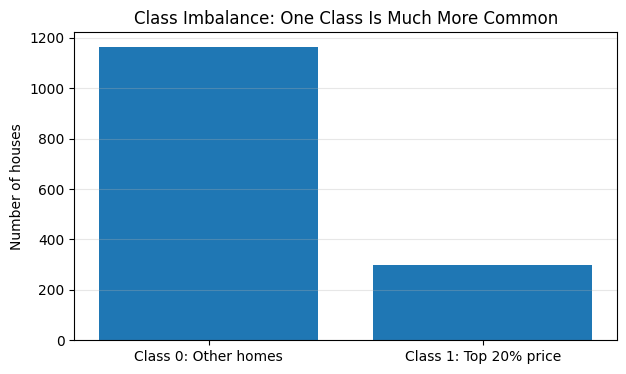

In [21]:
# Visualize how uneven the two classes are.
class_counts = y_imbalanced.value_counts().sort_index()

plt.figure(figsize=(7, 4))
plt.bar(
    ["Class 0: Other homes", "Class 1: Top 20% price"],
    class_counts.values
)
plt.ylabel("Number of houses")
plt.title("Class Imbalance: One Class Is Much More Common")
plt.grid(axis="y", alpha=0.3)
plt.show()

### What this graph shows

One bar is much taller because class `0` contains about 80% of the houses.

That creates the trap:

```text
predict class 0 every time
-> correct for most rows
-> high accuracy
-> but the model learns nothing useful about class 1
```

The graph makes it easier to see **why accuracy alone can be misleading** when one class dominates the dataset.

# 9. Classification Thresholds

A classifier usually produces a **score or probability first**.

Example:

```text
House A -> 0.82 probability of being above $200k
House B -> 0.42 probability of being above $200k
```

A **threshold** is the cutoff that turns the probability into a final class.

With threshold `0.5`:

```text
House A: 0.82 >= 0.5 -> positive
House B: 0.42 <  0.5 -> negative
```

Now change the threshold to `0.3`:

```text
House A: positive
House B: positive
```

The model itself did not change.

The probabilities did not change.

Only our **decision rule** changed.

### Why does this matter?

Lower threshold:

```text
easier to call something positive
-> catch more real positives
-> recall usually increases
-> false positives usually increase
```

Higher threshold:

```text
harder to call something positive
-> fewer positive predictions
-> precision often increases
-> more real positives may be missed
```

So there is no universally correct threshold.

The right threshold depends on the real-world cost of:

```text
false positives
vs
false negatives
```

> **Choose or tune thresholds using validation data, then freeze the choice before the final test.**

In [22]:
# Compare several probability cutoffs.
rows = []

for threshold in [0.3, 0.5, 0.7]:
    predictions = (
        class_probabilities >= threshold
    ).astype(int)

    rows.append({
        "threshold": threshold,
        "precision": precision_score(y_val_c, predictions),
        "recall": recall_score(y_val_c, predictions),
        "F1": f1_score(y_val_c, predictions)
    })

# Save the results so we can use the same values in a graph.
threshold_results = pd.DataFrame(rows)
threshold_results.round(3)

,threshold,precision,recall,F1
0,0.3,0.724,0.859,0.786
1,0.5,0.887,0.734,0.803
2,0.7,0.950,0.594,0.731


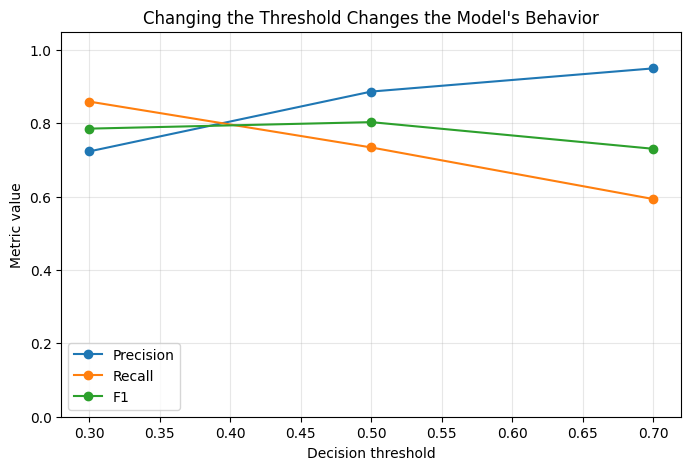

In [23]:
# Plot how precision, recall, and F1 change when the threshold changes.
plt.figure(figsize=(8, 5))
plt.plot(
    threshold_results["threshold"],
    threshold_results["precision"],
    marker="o",
    label="Precision"
)
plt.plot(
    threshold_results["threshold"],
    threshold_results["recall"],
    marker="o",
    label="Recall"
)
plt.plot(
    threshold_results["threshold"],
    threshold_results["F1"],
    marker="o",
    label="F1"
)
plt.xlabel("Decision threshold")
plt.ylabel("Metric value")
plt.title("Changing the Threshold Changes the Model's Behavior")
plt.ylim(0, 1.05)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### How to read the threshold graph

Move from left to right as the threshold becomes stricter.

```text
threshold = 0.3
-> easier to predict positive
-> usually catches more positives
-> recall tends to be higher

threshold = 0.7
-> harder to predict positive
-> fewer positive predictions
-> precision may improve
-> recall may fall
```

The important lesson is:

> **Changing the threshold does not retrain the model. It changes how we turn the model's probability into a decision.**

There is no universal best threshold. The choice depends on whether false positives or false negatives are more costly.

### What the table gives you

The table gives the exact precision, recall, and F1 values for each threshold.

The graph above makes the same trade-off easier to see visually; the table is useful when you need the exact numbers.

# 10. ROC-AUC and PR-AUC

Accuracy, precision, recall, and F1 usually depend on a **specific threshold**.

ROC-AUC and PR-AUC help us evaluate the model across **many possible thresholds**.

---

## ROC Curve and ROC-AUC

The ROC curve compares:

```text
True Positive Rate
-> same idea as recall

False Positive Rate
-> fraction of real negatives incorrectly predicted positive
```

Each possible threshold gives us a different point on the curve.

A useful interpretation of ROC-AUC is:

> **If we randomly choose one positive example and one negative example, how often does the model give the positive example a higher score?**

Example:

```text
ROC-AUC = 0.90
```

roughly means the model is very good at ranking positive examples above negative examples.

Mental scale:

```text
1.0 -> perfect ranking
0.5 -> roughly random ranking
```

On the ROC graph:

```text
x-axis -> false positive rate
y-axis -> true positive rate / recall

closer to the top-left -> better
diagonal line -> roughly random
```

---

## Precision-Recall Curve and PR-AUC

The Precision-Recall curve asks a different question:

> **As we try to catch more positive examples, how much precision do we keep?**

When we lower the threshold:

```text
recall tends to increase
but
precision may decrease
```

The PR curve shows that trade-off.

PR-AUC summarizes the area under that curve.

```text
higher PR-AUC
-> model maintains stronger precision while reaching higher recall
```

PR-AUC is especially useful when the positive class is rare, such as fraud or failure detection.

### Simple difference

```text
ROC-AUC
-> how well positives are ranked above negatives overall

PR-AUC
-> how well precision holds up while recall changes
-> often more informative for rare positive classes
```

In [24]:
# ROC-AUC from validation probabilities.
roc_auc = roc_auc_score(
    y_val_c,
    class_probabilities
)

# Build the Precision-Recall curve.
precisions, recalls, _ = precision_recall_curve(
    y_val_c,
    class_probabilities
)

# Compute the actual area under the PR curve.
pr_auc = auc(
    recalls,
    precisions
)

print("ROC-AUC:", round(roc_auc, 3))
print("PR-AUC :", round(pr_auc, 3))

ROC-AUC: 0.948
PR-AUC : 0.89


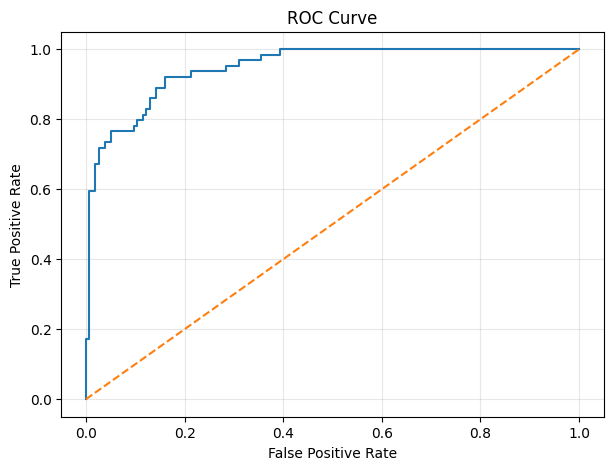

In [25]:
# Calculate False Positive Rate and True Positive Rate
# at many possible probability thresholds.
fpr, tpr, _ = roc_curve(
    y_val_c,
    class_probabilities
)

plt.figure(figsize=(7, 5))

# Model ROC curve.
plt.plot(fpr, tpr)

# Diagonal reference line: roughly random guessing.
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.grid(alpha=0.3)
plt.show()

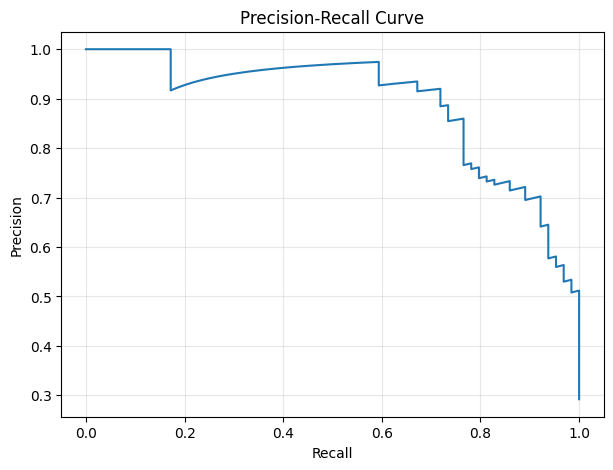

In [26]:
# precisions and recalls were calculated in the previous metric cell.
plt.figure(figsize=(7, 5))

plt.plot(
    recalls,
    precisions
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.grid(alpha=0.3)
plt.show()

### How to read the ROC and Precision-Recall graphs

## ROC graph

```text
x-axis = False Positive Rate
         how many real negatives we incorrectly call positive

y-axis = True Positive Rate / Recall
         how many real positives we successfully catch
```

The diagonal line represents roughly random ranking.

A useful model tries to move toward the **top-left**:

```text
high true-positive rate
with
low false-positive rate
```

ROC-AUC summarizes the whole ROC curve into one number.

---

## Precision-Recall graph

```text
x-axis = Recall
         how many real positives we catch

y-axis = Precision
         how trustworthy our positive predictions are
```

As we try to catch more positives, precision can fall because we start accepting less-certain cases.

A stronger classifier keeps the curve **higher** while recall increases.

This graph is especially useful when positive examples are rare.

# 11. Calibration

Classification models can output probabilities.

But a probability is only useful if the number is meaningful.

**Calibration asks whether predicted probabilities match what actually happens.**

Example:

Suppose the model finds 100 houses and gives each one a probability close to:

```text
0.80
```

If the model is well calibrated, we would expect roughly:

```text
80 of those 100 houses
```

to actually belong to the positive class.

### A model can rank well but still be poorly calibrated

Imagine:

```text
Model says: 99% probability
Reality: only about 75% of those examples are positive
```

The model might still correctly know which examples are more likely than others.

But its probability is **too confident**.

### How to read the calibration graph

```text
x-axis -> average predicted probability
y-axis -> actual fraction that were positive
```

Perfect calibration follows the diagonal:

```text
predicted 20% -> about 20% actually positive
predicted 60% -> about 60% actually positive
predicted 90% -> about 90% actually positive
```

If a point is:

```text
below the diagonal
-> predicted probability is higher than reality
-> model is overconfident

above the diagonal
-> reality is higher than predicted
-> model is underconfident
```

Calibration matters when the probability itself affects decisions, such as:

```text
risk scores
fraud review queues
medical decision support
confidence-based automation
```

The Brier score used below measures probability prediction error. Lower is better, but remember that Brier score reflects more than calibration alone.

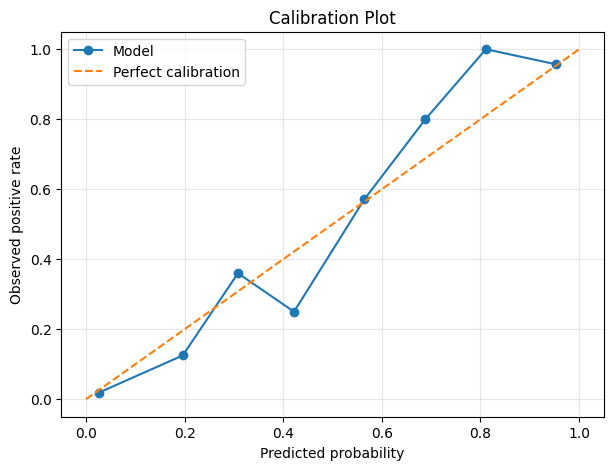

Brier score: 0.082


In [27]:
# Group predictions into probability bins.
# prob_pred = average predicted probability in each bin
# prob_true = actual positive rate in that bin
prob_true, prob_pred = calibration_curve(
    y_val_c,
    class_probabilities,
    n_bins=8
)

plt.figure(figsize=(7, 5))

# Model calibration line.
plt.plot(
    prob_pred,
    prob_true,
    marker="o",
    label="Model"
)

# Perfect calibration would follow this diagonal.
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

plt.xlabel("Predicted probability")
plt.ylabel("Observed positive rate")
plt.title("Calibration Plot")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Brier score measures probability error. Lower is better.
brier = brier_score_loss(
    y_val_c,
    class_probabilities
)

print("Brier score:", round(brier, 3))

### How to read the calibration graph

The diagonal line is the ideal case.

A point near:

```text
x = 0.70
y = 0.70
```

means:

```text
model predicted about 70%
and
about 70% were actually positive
```

That is good calibration.

If a point is **below** the diagonal:

```text
predicted probability > actual positive rate
-> model is too confident
```

If a point is **above** the diagonal:

```text
actual positive rate > predicted probability
-> model is not confident enough
```

So this graph is not mainly asking "Did the model classify correctly?"

It is asking:

> **Can we trust the probability number itself?**

The Brier score below measures overall probability error. Lower is better, but it reflects more than calibration alone.

# 12. Cross-Validation

A single validation split gives us only **one sample of model performance**.

Maybe the validation set happened to contain easy houses.

Or difficult houses.

Then our score may depend too much on that one split.

**Cross-validation evaluates the same modeling approach several times using different parts of the development data as validation data.**

## What is a fold?

A **fold** is simply one chunk of the dataset.

With 5-fold cross-validation:

```text
divide development data into 5 chunks
```

Then repeat:

```text
Run 1:
validate on fold 1
train on folds 2,3,4,5

Run 2:
validate on fold 2
train on folds 1,3,4,5

Run 3:
validate on fold 3
...

until every fold has been validation once
```

So we train temporary models several times and get several validation scores.

Example:

```text
Fold 1 MAE = $24k
Fold 2 MAE = $26k
Fold 3 MAE = $25k
Fold 4 MAE = $23k
Fold 5 MAE = $27k
```

Now we know more than just:

```text
"my validation MAE is $25k"
```

We can see whether performance is fairly stable across different samples.

Cross-validation helps answer:

> **Does this modeling approach work consistently, or did we just get lucky with one validation split?**

Important:

```text
cross-validation -> development/model selection

final test set -> still untouched
```

The temporary cross-validation models are not the final deployed model. After making our choices, we train the final model on the available development data and evaluate once on the test set.

In [28]:
# Development data = training + validation.
# The final test set is intentionally excluded.
X_dev = pd.concat(
    [X_train, X_val]
)

y_dev = pd.concat(
    [y_train, y_val]
)

cv_model = Pipeline([
    ("scale", StandardScaler()),
    ("model", LinearRegression())
])

# KFold tells scikit-learn how to create the 5 folds.
#
# shuffle=True:
# mix the development examples before making folds
#
# random_state=42:
# make the same shuffled folds every time we rerun the notebook
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# cross_val_score will:
# 1. train a fresh pipeline on 4 folds
# 2. evaluate it on the remaining fold
# 3. repeat until every fold has been validation once
scores = cross_val_score(
    cv_model,
    X_dev,
    y_dev,
    cv=cv,
    scoring="neg_mean_absolute_error"
)

# scikit-learn uses negative MAE here because its scoring API
# follows a "higher score is better" convention.
#
# Multiplying by -1 turns the values back into normal MAE.
cv_mae = -scores

print("MAE for each fold:")
print(np.round(cv_mae, 2))

print(
    "\nAverage CV MAE: $",
    round(cv_mae.mean(), 2)
)

print(
    "Spread (standard deviation): $",
    round(cv_mae.std(), 2)
)

MAE for each fold:
[29565.05 31231.74 27466.32 27450.37 29794.37]

Average CV MAE: $ 29101.57
Spread (standard deviation): $ 1458.28


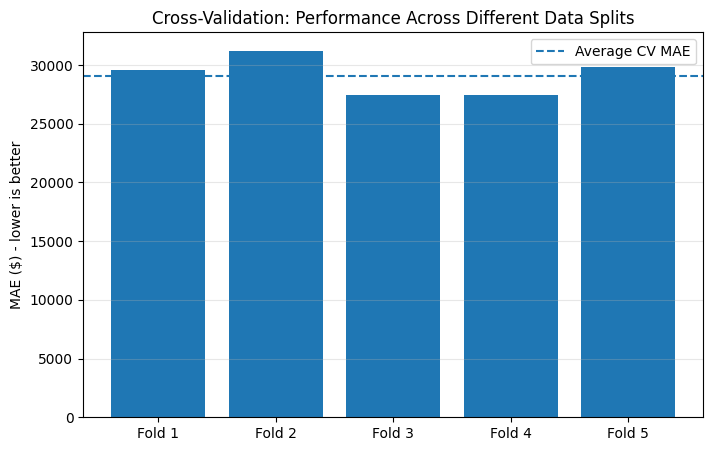

In [29]:
# Visualize the MAE from each cross-validation fold.
fold_labels = [f"Fold {i}" for i in range(1, len(cv_mae) + 1)]

plt.figure(figsize=(8, 5))
plt.bar(fold_labels, cv_mae)
plt.axhline(
    cv_mae.mean(),
    linestyle="--",
    label="Average CV MAE"
)
plt.ylabel("MAE ($) - lower is better")
plt.title("Cross-Validation: Performance Across Different Data Splits")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.show()

### How this graph explains cross-validation

Each bar comes from a **different validation fold**.

If the bars are fairly similar:

```text
performance is reasonably stable
across different samples of the data
```

If one or two bars are dramatically worse:

```text
the model may be sensitive to which examples
happen to be in the validation set
```

The dashed line is the average MAE across all folds.

This is why cross-validation gives us more information than trusting one validation split alone.

### Reading the numbers

The printed fold values give the exact MAE for each run.

```text
Average CV MAE
-> typical error across the folds

Standard deviation
-> how much those fold errors vary
```

Use the graph above for the visual pattern and these numbers for the exact values.

# 13. Final Test

By this point we have used training and validation data to:

```text
train models
study errors
compare complexity
inspect metrics
choose thresholds/settings
```

Now we stop making model choices.

We combine the development data and train the chosen workflow again.

Then we evaluate it once on the untouched test set.

```text
TRAIN + VALIDATION
-> build the final chosen model

TEST
-> final unbiased check
```

Why only now?

Because every time we use evaluation results to change the model, we are indirectly adapting to that evaluation data.

The final test set gives us the cleanest estimate in this notebook of how the chosen workflow may perform on similar unseen data.

For classification below we use the default threshold `0.5`.

If we had chosen a different threshold using validation data, we would freeze that threshold before evaluating on the test set.

In [30]:
# ----- Final regression model -----

# Combine train + validation now that development choices are finished.
X_train_final = pd.concat(
    [X_train, X_val]
)

y_train_final = pd.concat(
    [y_train, y_val]
)

final_reg_model = Pipeline([
    ("scale", StandardScaler()),
    ("model", LinearRegression())
])

final_reg_model.fit(
    X_train_final,
    y_train_final
)

# First and only final regression evaluation on X_test.
final_reg_predictions = final_reg_model.predict(
    X_test
)

final_reg_mae = mean_absolute_error(
    y_test,
    final_reg_predictions
)

print("Final regression test MAE: $", round(final_reg_mae, 2))

Final regression test MAE: $ 31030.64


In [31]:
# ----- Final classification model -----

# Combine classification train + validation data.
X_train_final_c = pd.concat(
    [X_train_c, X_val_c]
)

y_train_final_c = pd.concat(
    [y_train_c, y_val_c]
)

final_class_model = Pipeline([
    ("scale", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
])

final_class_model.fit(
    X_train_final_c,
    y_train_final_c
)

# Final predictions on the untouched classification test set.
final_class_probabilities = final_class_model.predict_proba(
    X_test_c
)[:, 1]

final_class_predictions = (
    final_class_probabilities >= 0.5
).astype(int)

print(
    "Final classification test accuracy:",
    round(accuracy_score(y_test_c, final_class_predictions), 3)
)

print(
    "Final classification test precision:",
    round(precision_score(y_test_c, final_class_predictions), 3)
)

print(
    "Final classification test recall:",
    round(recall_score(y_test_c, final_class_predictions), 3)
)

print(
    "Final classification test F1:",
    round(f1_score(y_test_c, final_class_predictions), 3)
)

Final classification test accuracy: 0.9
Final classification test precision: 0.818
Final classification test recall: 0.844
Final classification test F1: 0.831


# 14. Day 10 Mental Model

The whole Day 10 workflow is:

```text
RAW DATA
↓
PREPROCESS
prepare data correctly
↓
TRAIN
model learns from training examples
↓
VALIDATION / CROSS-VALIDATION
compare choices and study mistakes
↓
FREEZE YOUR CHOICES
stop tuning
↓
FINAL TEST
evaluate once on untouched data
```

Throughout the process:

```text
avoid leakage
watch for overfitting
use the right metric for the problem
do not let test data influence training
```

## Regression

```text
MAE
-> average size of prediction mistakes
-> easy to interpret in original units

MSE
-> squares errors
-> gives extra weight to large mistakes
```

## Classification

```text
Confusion Matrix
-> what types of mistakes happened?

Accuracy
-> what fraction of all predictions were correct?

Precision
-> when model predicts positive, how often is it right?

Recall
-> of all real positives, how many did it find?

F1
-> one score balancing precision and recall

Threshold
-> cutoff that converts probability into a class

ROC-AUC
-> overall ability to rank positives above negatives

PR-AUC
-> precision/recall trade-off across thresholds

Calibration
-> do predicted probabilities match observed frequencies?
```



# Why This Matters for AI Engineering

These ideas are not limited to house-price models.

Later you may evaluate:

```text
a classifier
a recommendation model
a RAG retriever
a reranker
an LLM
an agent
```

The metrics will change, but the evaluation mindset stays similar.

For example, with a RAG system you may ask:

```text
Did retrieval work on examples that were not used while tuning it?
Did I accidentally leak answers into the evaluation set?
Am I measuring the type of failure users actually care about?
Does performance remain stable across different groups of questions?
```

With an agent you may ask:

```text
How often does it complete the task?
How often does it choose the wrong tool?
How many important cases does it miss?
Does a new prompt actually improve performance,
or did it only improve on the examples I kept looking at?
```

> **Evaluation is how we move from "it seems to work" to "I have evidence that it works."**

# References used


- [Google ML Crash Course - Overfitting](https://developers.google.com/machine-learning/crash-course/overfitting/overfitting)
- [Google ML Crash Course - Train, validation, and test sets](https://developers.google.com/machine-learning/crash-course/overfitting/dividing-datasets)
- [scikit-learn - StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html)
- [scikit-learn - Common pitfalls and data leakage](https://scikit-learn.org/stable/common_pitfalls.html)
- [scikit-learn - Metrics and scoring](https://scikit-learn.org/stable/modules/model_evaluation.html)
- [scikit-learn - Probability calibration](https://scikit-learn.org/stable/modules/calibration.html)
- [scikit-learn - Cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html)

# 15. Practice

Try answering these without looking back first.

1. Why is evaluating a model on its training data not enough?

2. What is the difference between train, validation, and test data?

3. What does **generalization** mean?

4. What is preprocessing? Give three examples.

5. What problem is feature scaling trying to solve?

6. If a standardized value is `+1`, what does that roughly mean?

7. Why should `StandardScaler` learn its mean and standard deviation from training data only?

8. What is data leakage? Give one example.

9. What is overfitting, and what would you expect to see in training vs validation error?

10. If MAE is `$20,000`, what does that tell you?

11. Why does MSE react strongly to large mistakes?

12. What is the difference between a false positive and a false negative?

13. Precision asks what question?

14. Recall asks what question?

15. Why can `95% accuracy` describe a useless model?

16. What changes when you lower a classification threshold?

17. What does ROC-AUC tell you?

18. Why can PR-AUC be useful when positives are rare?

19. What does it mean for a model to be calibrated?

20. Why use cross-validation if we already have a validation set?

21. In the preprocessing code example, why do we call `fillna()`?

22. Why do we convert the `location` text column into numerical columns?

23. What does `fit_transform()` do when we use `StandardScaler` on training data?

24. Why do we use only `transform()` on validation/test data instead of another `fit_transform()`?
